In [2]:

# Importamos las librerias pandas, numpy, requests, mstplotlib, seaborn   para la carga, limpieza, análisis y visualización
import pandas as pd

import numpy as np

import requests

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

import matplotlib.ticker as mtick


In [3]:
# cargamos el archivo csv y le ponemos el nombre de df_pi al Dataframe.
df_pi= pd.read_csv(r"C:\Users\USUARIO\Downloads\base_datos_restaurantes_USA_v2 (3).csv", encoding= "utf-8")



### Auditoría de calidad antes de la limpieza
Se cuantifican duplicados exactos e identificadores repetidos. No se eliminan automáticamente: primero se deben inspeccionar para distinguir errores de registros legítimos.

In [4]:
# Consultamos la cantidad de los valores faltantes en cada columna con su respetivo porcentaje.
faltantes_antes = pd.DataFrame({
    'cantidad': df_pi.isna().sum(),
    'porcentaje': (df_pi.isna().mean() * 100).round(2)
}).sort_values('porcentaje', ascending=False)
display(faltantes_antes)


,cantidad,porcentaje
telefono_contacto,15166,50.55
correo_electronico,15072,50.24
preferencias_alimenticias,1403,4.68
promedio_gasto_comida,145,0.48
edad,101,0.34
id_persona,0,0.00
genero,0,0.00
apellido,0,0.00
nombre,0,0.00
frecuencia_visita,0,0.00


In [5]:
# Consultamos con la función describe(include= "all") la estadística descriptiva en las columnas numéricas y tambien observamos las columnas no númericas podemos,  observar valores fuera de los parametros normales para corregirlos, además observamos valores outlier en las columna promedio gasto en comida e ingresos mensuales.
df_pi.describe(include= "all")

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
count,3.000000e+04,30000,30000,29899.000000,30000,30000,30000,30000.000000,29855.000000,30000,30000,28597,30000,14834,14928,30000,30000.000000
unique,NaN,690,1000,NaN,2,10,4,NaN,NaN,2,2,6,2,14834,14474,4,NaN
top,NaN,Michael,Smith,NaN,Femenino,Chicago,Medio,NaN,NaN,No,Sí,Carnes,No,(830)220-1926,pjohnson@example.org,Efectivo,NaN
freq,NaN,678,636,NaN,15044,5384,9325,NaN,NaN,15094,18483,7916,17155,1,4,11813,NaN
mean,5.504765e+09,NaN,NaN,49.665006,NaN,NaN,NaN,3.896133,32.603452,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5389.755867
std,2.602799e+09,NaN,NaN,23.839550,NaN,NaN,NaN,2.741532,26.402601,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4538.491728
min,1.000153e+09,NaN,NaN,-5.000000,NaN,NaN,NaN,-3.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,800.000000
25%,3.243617e+09,NaN,NaN,33.000000,NaN,NaN,NaN,2.000000,13.290000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1860.000000
50%,5.515865e+09,NaN,NaN,49.000000,NaN,NaN,NaN,4.000000,25.510000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3402.000000
75%,7.754426e+09,NaN,NaN,65.000000,NaN,NaN,NaN,5.000000,44.400000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7761.000000


In [6]:
# Calculamos el coeficiente de variacióen en la columna edad para verificar si se imputa la media los valores cercanos a cero nos muestran consistencia en los datos lo que nos permite reflejar que existe una dispersion cosiderable en los datos.
cv = 23.83954960148132 / 49.665005518579214 *100
cv

48.00069858557283

In [7]:
# Calculamos el coeficiente de variacióen en la columna frecuencia_visita para verificar si se imputa la media los valores cercanos a cero nos muestran consistencia en los datos lo que nos permite reflejar que existe una dispersion cosiderable en los datos por lo tanto decidimos imputarle la mediana.
cv = 2.741531612452236 / 3.8961333333333332 *100
cv

70.36544640290124

In [8]:
# Calculamos el coeficiente de variacióen en la columna  promedio_gasto_comida para verificar si se imputa la media los valores cercanos a cero nos muestran consistencia en los datos lo que nos permite reflejar que existe una dispersion cosiderable en los datos valores  por consiguiente decidimos imputarle el valor de la mediana que no  se ve afectada por valores extremos.
cv = 26.402600946984908 / 32.603451683135155  * 100
cv

80.9809992008982

In [9]:
# Revisamos la columna id_persona para verificar que no haya duplicados y observamos que no se presentan para lo cual utilziamos la funcionn duplicated.
df_pi["id_persona"].duplicated().sum()

np.int64(0)

In [10]:
# consultamos la informacion general de Dataframe donde observamos que en la columna edad tenemos valores nulos, en la columna promedio_gasto_comida, preferencias alimenticias, telefono e contacto, correo electronico.  
informacion_general = df_pi.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_persona                 30000 non-null  int64  
 1   nombre                     30000 non-null  str    
 2   apellido                   30000 non-null  str    
 3   edad                       29899 non-null  float64
 4   genero                     30000 non-null  str    
 5   ciudad_residencia          30000 non-null  str    
 6   estrato_socioeconomico     30000 non-null  str    
 7   frecuencia_visita          30000 non-null  int64  
 8   promedio_gasto_comida      29855 non-null  float64
 9   ocio                       30000 non-null  str    
 10  consume_licor              30000 non-null  str    
 11  preferencias_alimenticias  28597 non-null  str    
 12  membresia_premium          30000 non-null  str    
 13  telefono_contacto          14834 non-null  str    
 14  c

In [11]:
# Con la funciom isna podemos observar que en la columna edad tenemos el promedio de los valores nulos y en la columna  promedio_gasto_comida.
df_pi.isna().mean() * 100

id_persona                    0.000000
nombre                        0.000000
apellido                      0.000000
edad                          0.336667
genero                        0.000000
ciudad_residencia             0.000000
estrato_socioeconomico        0.000000
frecuencia_visita             0.000000
promedio_gasto_comida         0.483333
ocio                          0.000000
consume_licor                 0.000000
preferencias_alimenticias     4.676667
membresia_premium             0.000000
telefono_contacto            50.553333
correo_electronico           50.240000
tipo_de_pago_mas_usado        0.000000
ingresos_mensuales            0.000000
dtype: float64

In [12]:
# Observamos el Dataframe para darle una observacion general  al dataset.
df_pi

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
0,2550327378,Jackson,Gomez,31.0,Masculino,Miami,Alto,6,67.51,Sí,No,Vegetariano,Sí,(830)220-1926,NaN,Efectivo,6425
1,9446112038,Samantha,Soto,40.0,Femenino,Denver,Medio,2,44.92,Sí,Sí,Mariscos,No,881-476-1426,NaN,Efectivo,2374
2,3098363243,Terry,Adams,62.0,Femenino,Denver,Bajo,2,9.24,Sí,Sí,Vegetariano,No,NaN,diana74@example.net,Efectivo,1110
3,4013002847,James,Shannon,41.0,Masculino,Boston,Alto,5,30.74,Sí,Sí,Carnes,Sí,NaN,scottfrey@example.com,Tarjeta,6931
4,7372911048,Susan,Jones,49.0,Femenino,San Diego,Bajo,0,0.00,No,No,Carnes,No,243.248.8919,glassgary@example.org,Tarjeta,1350
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,4862097674,Robert,Cortez,20.0,Masculino,Houston,Alto,-3,30.82,Sí,Sí,Vegano,Sí,NaN,garciagregory@example.net,Tarjeta,5781
29996,9458262482,Michael,Holt,78.0,Masculino,Denver,Alto,5,45.04,No,No,Mariscos,No,NaN,jimmy77@example.org,Efectivo,7652
29997,3412365931,Rebecca,Henry,77.0,Femenino,San Diego,Muy Alto,7,93.55,No,Sí,Mariscos,Sí,NaN,NaN,Efectivo,12639
29998,8853079811,Tamara,Griffin,77.0,Femenino,Chicago,Bajo,1,6.18,Sí,No,Otro,No,(243)658-6543x11668,NaN,Tarjeta,1057


In [13]:
# Reemplazamos en la columna edad los valores que presntan valores por fuera de los parametros normales.

df_pi["edad"] = df_pi["edad"].replace(300,np.nan)
df_pi["edad"] = df_pi["edad"].replace(-5.0,np.nan)

In [14]:
# Imputamos  en la columna edad, a  los valores nulos el promedio de los datos  ya que se observa una simetría y convertimos los valores en enteros ya  que los decimales no tienen injerencia en la data de la columna edad.
df_pi["edad"]=df_pi["edad"].fillna(df_pi["edad"].mean())
df_pi["edad"] = df_pi["edad"].round(0).astype(int)

In [15]:
# Reemplazamos valores en la columna frecuencia visita ya que se registraba un valor de -3 y  el cual no es coherente con el la base de datos  y registra un valor anormal 0. y les imputamos la mediana ya que se observa asimetria en los datos de la columna por lo cual decidimos utilizarla.
df_pi["frecuencia_visita"] = df_pi["frecuencia_visita"].replace(-3,np.nan)
df_pi["frecuencia_visita"] = df_pi["frecuencia_visita"].replace(0,np.nan)
df_pi["frecuencia_visita"]=df_pi["frecuencia_visita"].fillna(df_pi["frecuencia_visita"].median())
df_pi["frecuencia_visita"] = df_pi["frecuencia_visita"].round().astype(int)

In [16]:

# Imputamos en la columna promedio_gasto_comida el valor de la mediana en los datos faltantes y donde enocntrabamos el valor 0.0  se utiliza la mediana porque en los valores de la columna se observa mucha dispersión y por lo tanto no se utiliza la media.
df_pi["promedio_gasto_comida"] = df_pi["promedio_gasto_comida"].replace(0.0,np.nan)
df_pi["promedio_gasto_comida"]=df_pi["promedio_gasto_comida"].fillna(df_pi["promedio_gasto_comida"].median())




In [17]:
# En la columna correo_electronico imputamos el string "sin dato" en los valores faltantes ya que no seria util imputarle otros valores.
df_pi["correo_electronico"]=df_pi["correo_electronico"].fillna("sin dato")

In [18]:
# Imputamos en la columna telefono_contacto el string "sin dato"  en los registros faltantes para no alterar los datos ya que no seria correcto imputarle otros valores.
df_pi["telefono_contacto"]=df_pi["telefono_contacto"].fillna("sin dato")

In [19]:
# Normalizamos la columna telefono:contacto para que los numeros queden en los mismos formatos.
mask = df_pi["telefono_contacto"] != "sin dato"

df_pi.loc[mask, "telefono_contacto"] = (
    df_pi.loc[mask, "telefono_contacto"]
    .str.replace(r"[().x\s]+", "-", regex=True)
    .str.replace(r"-+", "-", regex=True)
    .str.strip("-")
)

In [20]:
# Consultamos la información de la columna telefono_contato para observar la correcta imputación.
df_pi["telefono_contacto"]

0              830-220-1926
1              881-476-1426
2                  sin dato
3                  sin dato
4              243-248-8919
                ...        
29995              sin dato
29996              sin dato
29997              sin dato
29998    243-658-6543-11668
29999      295-679-7926-321
Name: telefono_contacto, Length: 30000, dtype: str

In [21]:
# Imputamos en la columna preferencias_alimenticas la moda  en los valores faltantes ya que es una variable cualitativa.
df_pi["preferencias_alimenticias"]=df_pi["preferencias_alimenticias"].fillna(df_pi["preferencias_alimenticias"].mode()[0] )

In [22]:
# consultamos la informacion para veriifcar que se hayan registrados los valores imputados
info_general= df_pi.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_persona                 30000 non-null  int64  
 1   nombre                     30000 non-null  str    
 2   apellido                   30000 non-null  str    
 3   edad                       30000 non-null  int64  
 4   genero                     30000 non-null  str    
 5   ciudad_residencia          30000 non-null  str    
 6   estrato_socioeconomico     30000 non-null  str    
 7   frecuencia_visita          30000 non-null  int64  
 8   promedio_gasto_comida      30000 non-null  float64
 9   ocio                       30000 non-null  str    
 10  consume_licor              30000 non-null  str    
 11  preferencias_alimenticias  30000 non-null  str    
 12  membresia_premium          30000 non-null  str    
 13  telefono_contacto          30000 non-null  str    
 14  c

In [23]:
# consultamos con la funcion isna el promedio de los valores nulos y observamos que ya no se presentan.
df_pi.isna().mean() * 100

id_persona                   0.0
nombre                       0.0
apellido                     0.0
edad                         0.0
genero                       0.0
ciudad_residencia            0.0
estrato_socioeconomico       0.0
frecuencia_visita            0.0
promedio_gasto_comida        0.0
ocio                         0.0
consume_licor                0.0
preferencias_alimenticias    0.0
membresia_premium            0.0
telefono_contacto            0.0
correo_electronico           0.0
tipo_de_pago_mas_usado       0.0
ingresos_mensuales           0.0
dtype: float64

In [24]:
# Realizamos una observación de todo el dataframe y podemos observar a través de la exteción Data Wrangler que  en las columnas no hacen falta valores.
df_pi.head(30000)

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
0,2550327378,Jackson,Gomez,31,Masculino,Miami,Alto,6,67.51,Sí,No,Vegetariano,Sí,830-220-1926,sin dato,Efectivo,6425
1,9446112038,Samantha,Soto,40,Femenino,Denver,Medio,2,44.92,Sí,Sí,Mariscos,No,881-476-1426,sin dato,Efectivo,2374
2,3098363243,Terry,Adams,62,Femenino,Denver,Bajo,2,9.24,Sí,Sí,Vegetariano,No,sin dato,diana74@example.net,Efectivo,1110
3,4013002847,James,Shannon,41,Masculino,Boston,Alto,5,30.74,Sí,Sí,Carnes,Sí,sin dato,scottfrey@example.com,Tarjeta,6931
4,7372911048,Susan,Jones,49,Femenino,San Diego,Bajo,4,27.05,No,No,Carnes,No,243-248-8919,glassgary@example.org,Tarjeta,1350
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,4862097674,Robert,Cortez,20,Masculino,Houston,Alto,4,30.82,Sí,Sí,Vegano,Sí,sin dato,garciagregory@example.net,Tarjeta,5781
29996,9458262482,Michael,Holt,78,Masculino,Denver,Alto,5,45.04,No,No,Mariscos,No,sin dato,jimmy77@example.org,Efectivo,7652
29997,3412365931,Rebecca,Henry,77,Femenino,San Diego,Muy Alto,7,93.55,No,Sí,Mariscos,Sí,sin dato,sin dato,Efectivo,12639
29998,8853079811,Tamara,Griffin,77,Femenino,Chicago,Bajo,1,6.18,Sí,No,Otro,No,243-658-6543-11668,sin dato,Tarjeta,1057


In [25]:
# Consultamos la columna "preferencias_alimenticias" para verificar la correcta imputación
df_pi.head(10)["preferencias_alimenticias"]


0    Vegetariano
1       Mariscos
2    Vegetariano
3         Carnes
4         Carnes
5         Carnes
6         Vegano
7    Vegetariano
8    Vegetariano
9         Carnes
Name: preferencias_alimenticias, dtype: str

In [26]:
# Con la función unique podemos verificar los valores unicos con lo cual podemos observar las ciudades que registra la base de datos.
df_pi["ciudad_residencia"].unique()

<StringArray>
[    'Miami',    'Denver',    'Boston', 'San Diego',    'Dallas',       'NYC',
   'Seattle',   'Chicago',   'Houston',   'Phoenix']
Length: 10, dtype: str

Filtramos la base de datos por la ciudad seleccionada escogemos Miami.

In [27]:
#  Filtramos la base de datos por la ciudad escogida Miami y  creamos la variable df_seleccion para nombrar al Dataframe de la ciudad escogid elegimos la ciudad de miami por que presenta el mayor promedio gasto en comida y ademas es una ciudad Turitica y por ende comercial.
df_seleccion = df_pi[df_pi["ciudad_residencia"] == "Miami"]
df_seleccion

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
0,2550327378,Jackson,Gomez,31,Masculino,Miami,Alto,6,67.51,Sí,No,Vegetariano,Sí,830-220-1926,sin dato,Efectivo,6425
16,6139475525,Andrew,Soto,18,Masculino,Miami,Muy Alto,9,26.60,Sí,Sí,Vegetariano,Sí,2859380942,ssteele@example.net,App,13452
37,5358661821,Elizabeth,Brown,79,Femenino,Miami,Muy Alto,6,28.43,No,No,Mariscos,Sí,464-992-9070-38394,sin dato,Efectivo,14072
45,8593345998,Robert,Wilson,76,Masculino,Miami,Alto,5,43.00,Sí,No,Mariscos,Sí,sin dato,sin dato,App,6528
47,6170452916,Bruce,Young,55,Masculino,Miami,Muy Alto,5,119.85,Sí,No,Carnes,Sí,sin dato,ltran@example.com,Efectivo,15844
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29953,2238067088,Kevin,Taylor,45,Masculino,Miami,Medio,5,35.35,Sí,No,Vegetariano,Sí,+1-748-240-5443,jerrychavez@example.com,Efectivo,3174
29957,1161504159,Rachael,Martinez,58,Femenino,Miami,Medio,5,19.10,No,Sí,Pescado,No,7756404909,wmalone@example.net,Efectivo,2157
29958,9452988778,William,Peters,50,Masculino,Miami,Bajo,2,14.65,Sí,Sí,Mariscos,No,sin dato,sin dato,Tarjeta,829
29985,8301681475,Gloria,Evans,38,Femenino,Miami,Alto,5,16.84,Sí,No,Carnes,Sí,950-647-8528-2958,marywilliams@example.net,Tarjeta,4853


In [28]:
# Consultamos la informacion general  de la base de datos filtrada por la ciudad escogida Miami y observamos que tiene 3186 entrdas y 17 columnas no presenta valores nulos.
info_general= df_seleccion.info()

<class 'pandas.DataFrame'>
Index: 3186 entries, 0 to 29988
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_persona                 3186 non-null   int64  
 1   nombre                     3186 non-null   str    
 2   apellido                   3186 non-null   str    
 3   edad                       3186 non-null   int64  
 4   genero                     3186 non-null   str    
 5   ciudad_residencia          3186 non-null   str    
 6   estrato_socioeconomico     3186 non-null   str    
 7   frecuencia_visita          3186 non-null   int64  
 8   promedio_gasto_comida      3186 non-null   float64
 9   ocio                       3186 non-null   str    
 10  consume_licor              3186 non-null   str    
 11  preferencias_alimenticias  3186 non-null   str    
 12  membresia_premium          3186 non-null   str    
 13  telefono_contacto          3186 non-null   str    
 14  correo_

In [29]:
# Consultamos con la función describe la estadística descriptiva en las columnas numéricas de la ciudad selecionada podemos  podemos observar que no se presentan valores nulos.

df_seleccion.describe()

,id_persona,edad,frecuencia_visita,promedio_gasto_comida,ingresos_mensuales
count,3.186000e+03,3186.000000,3186.000000,3186.000000,3186.000000
mean,5.469902e+09,49.081607,4.866918,40.623412,6476.256748
std,2.625106e+09,17.791085,2.057843,27.452360,4823.680223
min,1.005012e+09,18.000000,1.000000,10.000000,800.000000
25%,3.170965e+09,34.000000,4.000000,20.692500,2449.500000
50%,5.471511e+09,49.000000,5.000000,31.435000,5206.000000
75%,7.744773e+09,64.750000,6.000000,53.910000,9042.000000
max,9.999546e+09,80.000000,10.000000,129.500000,17998.000000


In [30]:
# con la funcion value_counts podemos observar las edades que mas frecuencia registran en la ciudad seleccionada podemos observar que la edad con mayores regitros es de 49.
df_seleccion["edad"].value_counts()


edad
49    97
44    72
34    67
38    65
50    63
      ..
74    41
25    40
64    39
21    38
29    36
Name: count, Length: 63, dtype: int64

In [31]:
# Con la funcion value_counts podemos observamos que estrato_socioeconomico se presenta con mayor frecuencia el cual el alto presenta mayor cantidad de registros.
df_seleccion["estrato_socioeconomico"].value_counts()

estrato_socioeconomico
Alto        1159
Muy Alto     799
Medio        783
Bajo         445
Name: count, dtype: int64

In [32]:
# Creamos Dataframe Porcentaje_alimenticias y Filtramos  y creamos la data por preferencias_alimenticias y podemos observar que la preferencia que mayor registros son los mariscos debido a que es una ciudad costera.
Porcentaje_alimenticias = df_seleccion["preferencias_alimenticias"].value_counts()
porcentajes = (Porcentaje_alimenticias / Porcentaje_alimenticias.sum() * 100).round(1)
pd.DataFrame({"count": Porcentaje_alimenticias, "porcentaje_%": porcentajes})

,count,porcentaje_%
preferencias_alimenticias,,
Mariscos,819,25.7
Vegetariano,728,22.8
Carnes,657,20.6
Vegano,382,12.0
Pescado,307,9.6
Otro,293,9.2


In [33]:
# Creamos el Dataframe para observar el porcentaje de los estratos socioeconomicos en la ciudad de Miami.
estrato= df_seleccion["estrato_socioeconomico"].value_counts()
porcentaje_estrato = (estrato / estrato.sum() * 100).round(1)
pd.DataFrame({"count": estrato, "porcentaje_%": porcentaje_estrato})

,count,porcentaje_%
estrato_socioeconomico,,
Alto,1159,36.4
Muy Alto,799,25.1
Medio,783,24.6
Bajo,445,14.0


In [34]:
# Agrupamos la data por frecuencia de visita y preferencias alimenticias para observar la cantidad y preferencia que mas visitas registran utilizamos el promedio.
df_seleccion.groupby("preferencias_alimenticias")["frecuencia_visita"].mean()

preferencias_alimenticias
Carnes         4.794521
Mariscos       4.821734
Otro           4.996587
Pescado        4.752443
Vegano         4.913613
Vegetariano    4.954670
Name: frecuencia_visita, dtype: float64

In [35]:
# Observamos que el promedio de gasto en comida y observamos que el registro con mas frecuencia es de 27.05 con 119 registros.
df_seleccion["promedio_gasto_comida"].value_counts()

promedio_gasto_comida
27.05    119
25.36      5
18.28      5
23.78      5
22.50      4
        ... 
68.44      1
19.10      1
14.65      1
16.84      1
15.65      1
Name: count, Length: 2433, dtype: int64

In [38]:
# Agrupamos la data por estrato socioeconomico y promedio de gasto en comida para observar la personas qe mas gastan según su estrato socioeconomico  y evidenciamos   por logica  de poder adquisitivo son las de mayor estrato.
df_seleccion.groupby("estrato_socioeconomico")["promedio_gasto_comida"].mean()

estrato_socioeconomico
Alto        40.035988
Bajo        19.540382
Medio       24.912248
Muy Alto    68.614168
Name: promedio_gasto_comida, dtype: float64

In [ ]:
# Agrupos  la data por estrato socieconomico y  frecuencia_visita por la media y observamos que el estrato que más presenta visitas es el Muy Alto.
df_seleccion.groupby("estrato_socioeconomico")["frecuencia_visita"].mean()

estrato_socioeconomico
Alto        4.950820
Bajo        2.600000
Medio       3.532567
Muy Alto    7.315394
Name: frecuencia_visita, dtype: float64

In [ ]:
# Analizamos  que a traves de la función value_counts podemos observar que el genero Masculino  presenta 44 registros mas que el genero femenino por lo cual evidenciamos que no hay una evidencia significativa.
df_seleccion["genero"].value_counts()

genero
Masculino    1615
Femenino     1571
Name: count, dtype: int64

In [ ]:
# Agrupamos la data por genero y frecuencia visita para observar la cantidad de visitas que se registraron por genero y evidenciamos que se prensenta en un  porcentaje similar
df_seleccion.groupby("genero")["frecuencia_visita"].mean()

genero
Femenino     4.854870
Masculino    4.878638
Name: frecuencia_visita, dtype: float64

In [ ]:
# Agrupamos la data por genero y promedio de gasto en comida ´podemos observar que es muy similar el gasto con una ligera diferencia donde gasta mas el genro femenino.
df_seleccion.groupby("genero")["promedio_gasto_comida"].mean()

genero
Femenino     40.846773
Masculino    40.406136
Name: promedio_gasto_comida, dtype: float64

In [ ]:

# Agrupamos la data por edad y frecuencia visita donde el promedio nos muestra que la frecuencia visita por edad oscila entre 3 y 4.8 en el promedio de frecuencia vista.
df_seleccion.groupby("edad")["frecuencia_visita"].mean()

edad
18    5.357143
19    5.111111
20    4.727273
21    4.342105
22    5.297872
        ...   
76    5.163636
77    4.716981
78    4.792453
79    4.313725
80    4.647059
Name: frecuencia_visita, Length: 63, dtype: float64

In [ ]:
# Agrupamos la data por membresia premium y frecuencia de visita con lo que podemos identificar que las personas con membresias visitan mas los negocios.
df_seleccion.groupby("membresia_premium")["frecuencia_visita"].mean()

membresia_premium
No    3.688338
Sí    5.904959
Name: frecuencia_visita, dtype: float64

In [ ]:
# Agrupamos el dataset de la ciudade Miami por membresia premium, promedio gasto en comida y frecuencia de visitas podemos observar que las personas con membresi gastan mas y regsitarn mayores visitas.
df_seleccion.groupby("membresia_premium").agg(gasto_promedio=("promedio_gasto_comida", "mean"), visitas=("frecuencia_visita", "count"))

,gasto_promedio,visitas
membresia_premium,,
No,27.560764,1492
Sí,52.128412,1694


In [ ]:
# Con la funcion  value_counts sacamos el número de pesona por ciudad para realizar el gráfico.
df_pi["ciudad_residencia"].value_counts()

ciudad_residencia
Chicago      5384
NYC          4769
Miami        3186
San Diego    3075
Dallas       2602
Boston       2547
Denver       2523
Houston      2212
Seattle      2191
Phoenix      1511
Name: count, dtype: int64

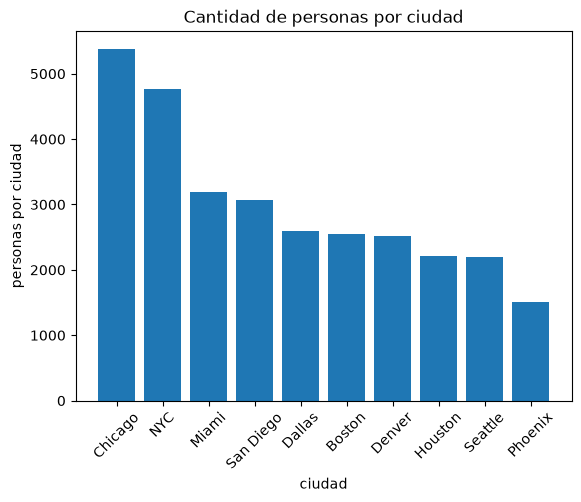

In [ ]:
#  Realizamos el gráfico de barras  para observar la cantidad de personas por ciudad que registra la base de datos de retaurantes observando que las que mayor cantidad de personas registra es Chicago, NYC, Miami.
cantidad = df_pi["ciudad_residencia"].value_counts()

fig, ax = plt.subplots()
ax.bar(cantidad.index, cantidad.values)
plt.title("Cantidad de personas por ciudad")
plt.xlabel("ciudad")
plt.ylabel("personas por ciudad")
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Generamos el listado de personas por estrato socioeconomico creamos dos variables para ordenar,  del muy alto al mas bajo y podemos identifiar que los estratos que mas registron presentan son Muy Alto y Alto
orden = ["Muy Alto", "Alto", "Medio", "Bajo"]
lista_estrato = df_pi["estrato_socioeconomico"].value_counts()
lista_estrato = lista_estrato.reindex(orden)

listado_estrato =lista_estrato.reset_index()
listado_estrato.columns = ["estrato_socioeconomico", "count"]
listado_estrato["porcentaje"] =(listado_estrato ["count"]/ listado_estrato ["count"].sum() * 100).round(2)

listado_estrato

,estrato_socioeconomico,count,porcentaje
0,Muy Alto,5476,18.25
1,Alto,9038,30.13
2,Medio,9325,31.08
3,Bajo,6161,20.54


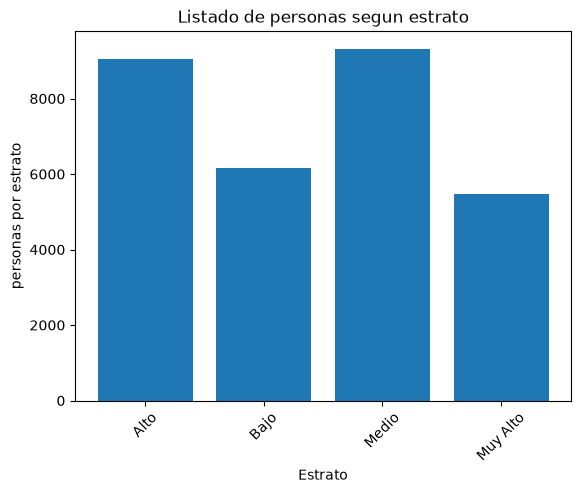

In [ ]:
#  Realizamos el gafico de barras  para observar la cantidad de personas por estrato que registra la base de datos de retaurantes observando que el estrato que registra mayor cantidad de personas es el Medio.
estrato = df_pi["estrato_socioeconomico"].value_counts().sort_index()

fig, ax = plt.subplots()
ax.bar(estrato.index, estrato.values)
plt.title("Listado de personas segun estrato")
plt.xlabel("Estrato")
plt.ylabel("personas por estrato")
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Agrupamos las columnas ciudad residencia por promedio gasto en comida y podemos observar que la ciudad que mas registra el promedio es Miami
df_pi.groupby("ciudad_residencia")["promedio_gasto_comida"].mean()

ciudad_residencia
Boston       30.954613
Chicago      26.852953
Dallas       30.234735
Denver       35.341946
Houston      27.738169
Miami        40.623412
NYC          38.598169
Phoenix      38.105685
San Diego    35.719304
Seattle      38.039251
Name: promedio_gasto_comida, dtype: float64

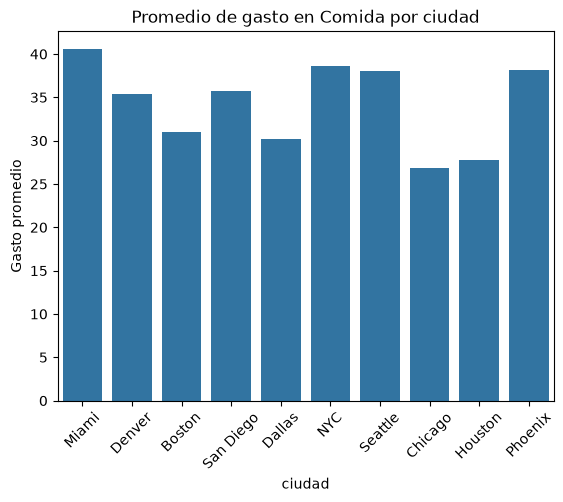

In [ ]:
# Generamos el gráfico en donde se muestra el gasto promedio en comida por ciudad y observamos las tres ciudades que mas gasto regitran son Miami, NYC, Seattle.
plt.figure()
ax =sns.barplot(
    data=df_pi,
    x= "ciudad_residencia",
    y= "promedio_gasto_comida",
    estimator= "mean",
    errorbar=None
)
plt.xticks(rotation=45)
plt.title("Promedio de gasto en Comida por ciudad")
plt.ylabel("Gasto promedio")
plt.xlabel("ciudad")
plt.show()

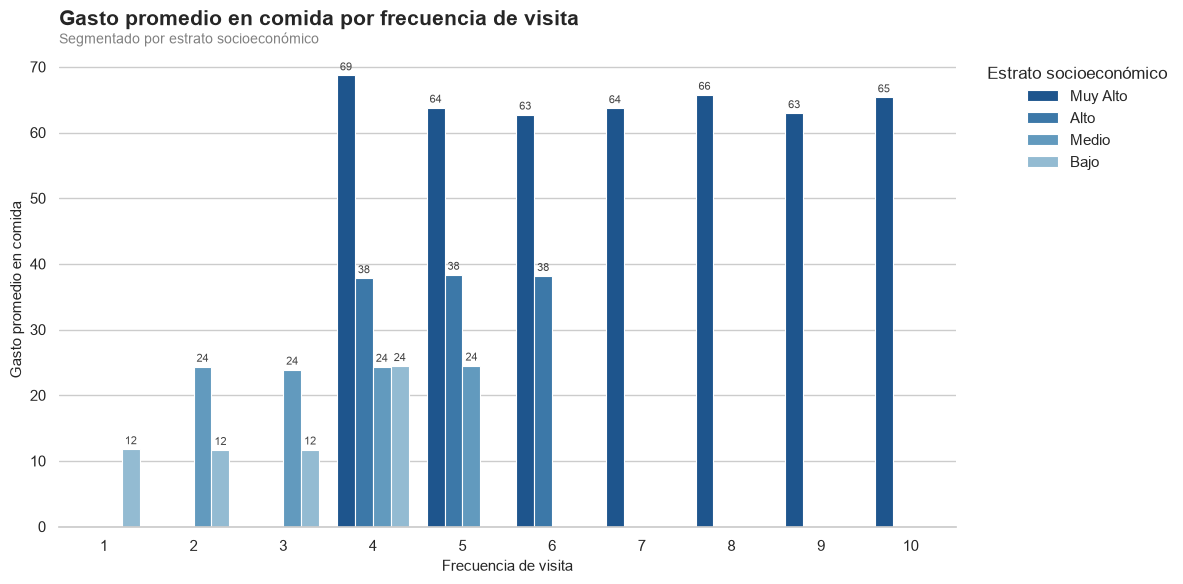

In [ ]:
# Generamos el gráfico donde se relacionan la frecuencia visitas con el gasto promedio en comida, segun el estrato socioeconomico uilizamos un barplot de seaborn y utilizamos un variable creada para dar orden al estrato socioeconomico, podemos observar que el estrato socioeconomico muy altoy alto son quienes mas gastan pormedio en comida y mas visitan por logica del  poder adquisitivo

sns.set_theme(style="whitegrid", context="notebook")

# Paleta de un solo color: más oscuro = estrato más alto
paleta = sns.color_palette("Blues_r", len(orden) + 2)[:len(orden)]

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=df_pi,
    x="frecuencia_visita",
    y="promedio_gasto_comida",
    hue="estrato_socioeconomico",
    hue_order=orden,
    palette=paleta,
    errorbar=None,
    edgecolor="white",
    linewidth=0.8,
    ax=ax,
)

# Etiquetas de valor sobre cada barra
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", padding=2, fontsize=8, color="#444")

# Títulos y ejes
ax.set_title("Gasto promedio en comida por frecuencia de visita",
             loc="left", fontsize=15, fontweight="bold", pad=20)
ax.text(0, 1.02, "Segmentado por estrato socioeconómico",
        transform=ax.transAxes, fontsize=10, color="gray")
ax.set_xlabel("Frecuencia de visita", fontsize=11)
ax.set_ylabel("Gasto promedio en comida", fontsize=11)
ax.set_ylim(0, None)  # el eje Y empieza en 0

# Leyenda fuera del gráfico, sin recuadro
ax.legend(title="Estrato socioeconómico", bbox_to_anchor=(1.02, 1),
          loc="upper left", frameon=False)

sns.despine(left=True)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()  # con paréntesis


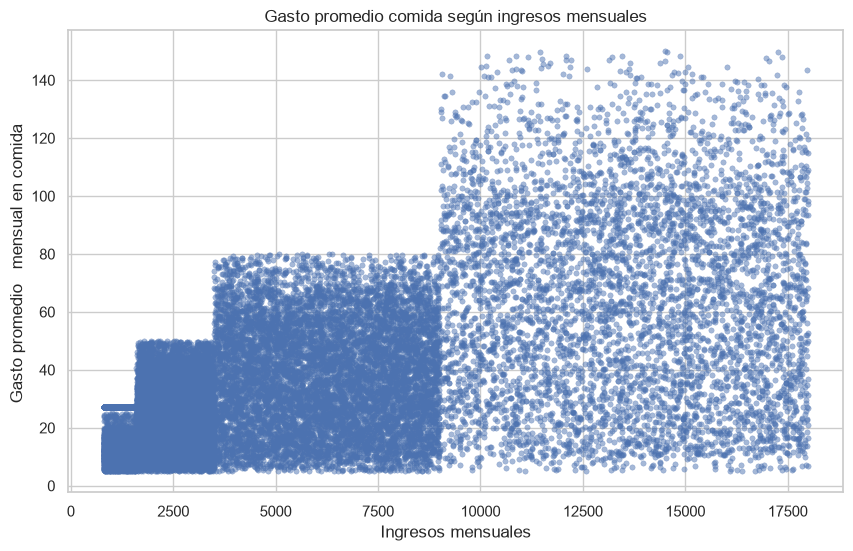

In [ ]:
# Generamos el grafico de dispersion y observamos que el promedio de gasto en comida se aumento en cunato mayor sean los igresos menuslaes y que los datos se encuentran agrupados.
plt.figure(figsize=(10,6))
sns.scatterplot(data=df_pi,
                x="ingresos_mensuales",
                y="promedio_gasto_comida",
                alpha=0.5, s=15, edgecolor=None)

plt.title("Gasto promedio comida según ingresos mensuales")
plt.xlabel("Ingresos mensuales")
plt.ylabel("Gasto promedio   mensual en comida ")
plt.show()

In [ ]:
# Calculamos el coefciente de correlación y se encotró una correlación positiva moderada-fuerte lo que apoya la hipotesis que entre mayores ingresos mayor gasto promedio en comida.
df_pi["ingresos_mensuales"].corr(df_pi["promedio_gasto_comida"])

np.float64(0.6126209669724457)

In [ ]:
# Creamos la variable conteo para realizar el garfico de como distribuyen las preferencias alimenticias en las diferentes ciudades de la base de datos.
conteo= df_pi["preferencias_alimenticias"].value_counts()
print(conteo)

preferencias_alimenticias
Carnes         9319
Vegetariano    6580
Mariscos       5212
Vegano         3267
Pescado        2983
Otro           2639
Name: count, dtype: int64


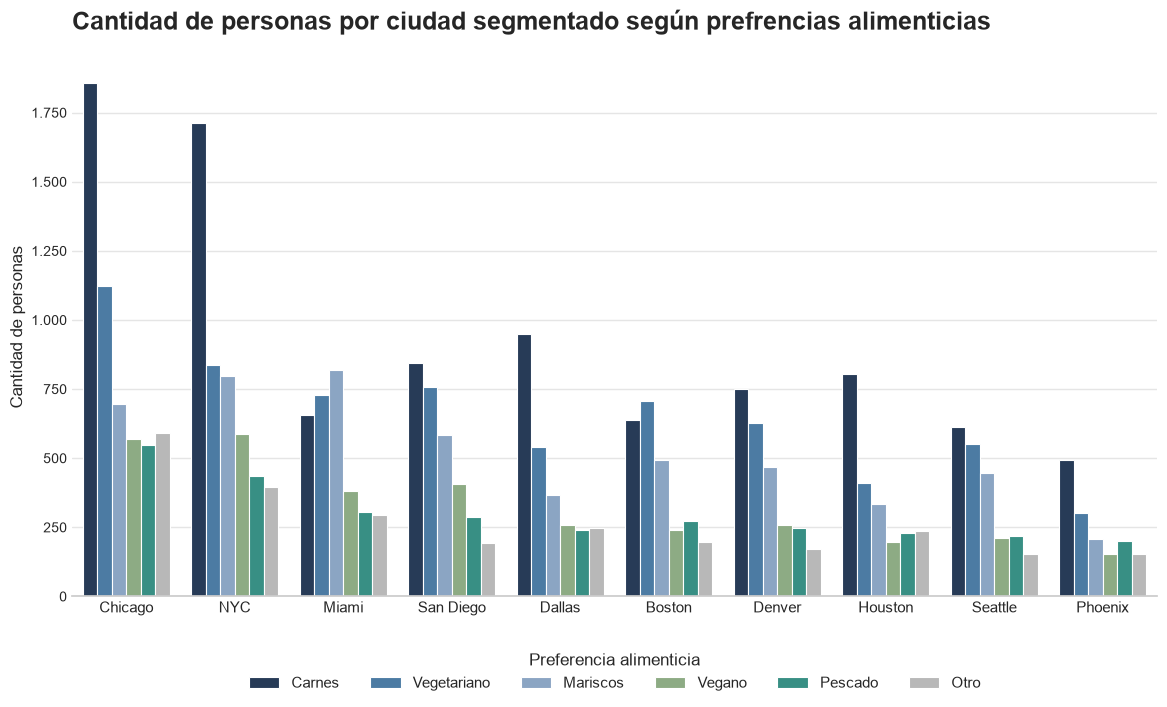

In [ ]:
# Creamos el grafico  donde se muestra las preferencias alimenticias por ciudad y podemos observar  que ciudades como NYC y Chicago con la preferecnia alimenticia con mayor registros es la carne, en la ciudad de Miami son los Mariscos por razones de ubicación geografica.

sns.set_theme(style="whitegrid")

# Orden: ciudades y preferencias de mayor a menor
orden_ciudades = df_pi["ciudad_residencia"].value_counts().index
orden_pref = df_pi["preferencias_alimenticias"].value_counts().index

# Paleta corporativa (ajusta los nombres si difieren de tus datos)
paleta = {
    "Carnes": "#1F3A5F",
    "Vegetariano": "#3E7CB1",
    "Mariscos": "#81A4CD",
    "Pescado": "#2A9D8F",
    "Vegano": "#8AB17D",
    "Otro": "#B8B8B8",
}

fig, ax = plt.subplots(figsize=(14, 7))

sns.countplot(
    data=df_pi,
    x="ciudad_residencia",
    hue="preferencias_alimenticias",
    order=orden_ciudades,
    hue_order=orden_pref,
    palette=paleta,
    edgecolor="white",
    linewidth=0.8,
    ax=ax,
)

# Títulos
ax.set_title("Cantidad de personas por ciudad segmentado según prefrencias alimenticias",
             fontsize=18, fontweight="bold", loc="left", pad=20)
ax.set_xlabel("")
ax.set_ylabel("Cantidad de personas", fontsize=12)

# Eje Y con separador de miles
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda v, _: f"{int(v):,}".replace(",", "."))
)

# Limpieza visual
sns.despine(left=True)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", color="#E5E5E5")
ax.tick_params(axis="x", labelsize=11, length=0)
ax.tick_params(axis="y", labelsize=10, length=0)

# Leyenda abajo, en una sola fila
ax.legend(
    title="Preferencia alimenticia",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=len(orden_pref),
    frameon=False,
)


In [ ]:
# Creamos la variable top_clientes para realizar el listado de las personas que mas gastan promedio en comida segun preferencia alimenticia y podemos observar que los 100 primeros registros presenta un gasto promedio en comidad  entre 135.83 y 149.97.
top_clientes = df_pi.nlargest(100, "promedio_gasto_comida")[
  [  "id_persona", "nombre", "apellido", 
              "promedio_gasto_comida", "preferencias_alimenticias"]]

In [ ]:
# Abrimos el listado de las personas con mayor gasto en comida por ciudad observamos que presentan un gasto entre 
top_clientes

,id_persona,nombre,apellido,promedio_gasto_comida,preferencias_alimenticias
24552,4603726279,Ebony,Smith,149.97,Mariscos
17940,5935112482,Julie,Taylor,149.89,Vegano
10712,1282449336,William,Hutchinson,149.73,Vegetariano
29849,5615233109,Anthony,Macdonald,149.68,Vegano
2828,6922359022,Kathy,Doyle,148.51,Mariscos
...,...,...,...,...,...
23310,6074251735,Alec,Guerra,136.42,Otro
18704,8536205444,Robin,Barnes,136.35,Carnes
17632,7215060019,Laura,Chen,135.89,Carnes
13322,5574389069,Melanie,Meyer,135.87,Carnes


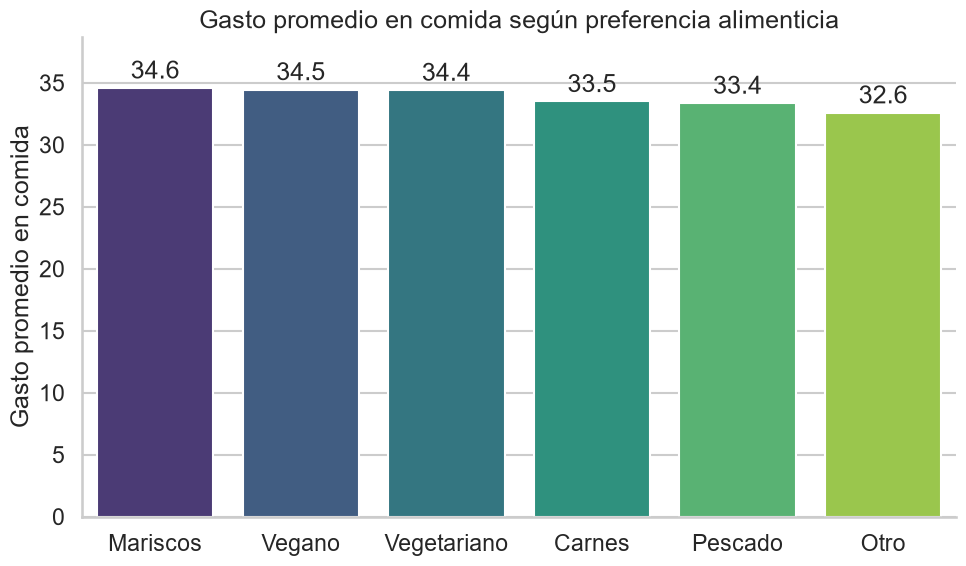

In [ ]:
# Creamos la variable resumen donde agrupamos las columnas preferencias_alimenticias, promedio_gasto_comida por la media y la cantidad para crear el grafico ordenado donde visualizamos el promedio gasto en comida por preferencia a, creamos la variable clientes podeos observar el promedio gasto en comida según preferencia alimenticai se encuentra por encima de 30 USD.
resumen = (
    df_pi.groupby("preferencias_alimenticias")
    .agg(gasto_promedio=("promedio_gasto_comida", "mean"),
         clientes=("promedio_gasto_comida", "count"))
    .reset_index()
    .sort_values("gasto_promedio", ascending=False)
)

sns.set_theme(style="whitegrid", context="talk")

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=resumen,
    x="preferencias_alimenticias",
    y="gasto_promedio",
    hue="preferencias_alimenticias",
    palette="viridis",
    legend=False,
)

for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.1f", padding=3)

ax.margins(y=0.12)
ax.set(
    title="Gasto promedio en comida según preferencia alimenticia",
    xlabel="",
    ylabel="Gasto promedio en comida",
)
sns.despine()
plt.tight_layout()
plt.show()


In [ ]:
# Se instala el la libreria nbformat para realizar el gráfico de las personas que mas gastan promedio en comida segmentado por la preferencia alimenticia
%pip install --upgrade nbformat

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# Creamo el gráfico con la 100 personas que más gastan   promedio en comida segun sus preferencias alimentcias e importamos la libreria plotly con el paquete express y la libreria nbformat para crear el gráfico interativo. podemos observar que  las personas que tiene un promedio de gasto en comida osila entre 136 y 149 y el mayor promedio lorealizan en carnes.
import plotly.express as px
fig = px.histogram(top_clientes,x="promedio_gasto_comida",
                   color="preferencias_alimenticias",
                   nbins=20, barmode="group")
fig.update_layout(title="Promedio de gasto en comida",
                  xaxis_title="Gasto promedio",
                  yaxis_title="Cantidad de personas",
                  bargap=0.1)
fig.show()


In [ ]:
# Filtramos las ciudades por las que tiene mayor cantidad de suscripción a la membresia y podemos observar que Chicago  es la ciudad que registra la la mayor cantidad

membresia_por_ciudad= df_pi.groupby("ciudad_residencia")["membresia_premium"].value_counts().reset_index(name="cantidad")

#filtramos sololos que tienen membresia
solo_premium = membresia_por_ciudad[membresia_por_ciudad["membresia_premium"] == "Sí"]

# ordenamos de mayor a menor
solo_premium.sort_values("cantidad", ascending=False)


,ciudad_residencia,membresia_premium,cantidad
3,Chicago,Sí,2215
13,NYC,Sí,1775
10,Miami,Sí,1694
17,San Diego,Sí,1502
1,Boston,Sí,1139
7,Denver,Sí,1068
19,Seattle,Sí,1023
5,Dallas,Sí,992
9,Houston,Sí,808
15,Phoenix,Sí,629


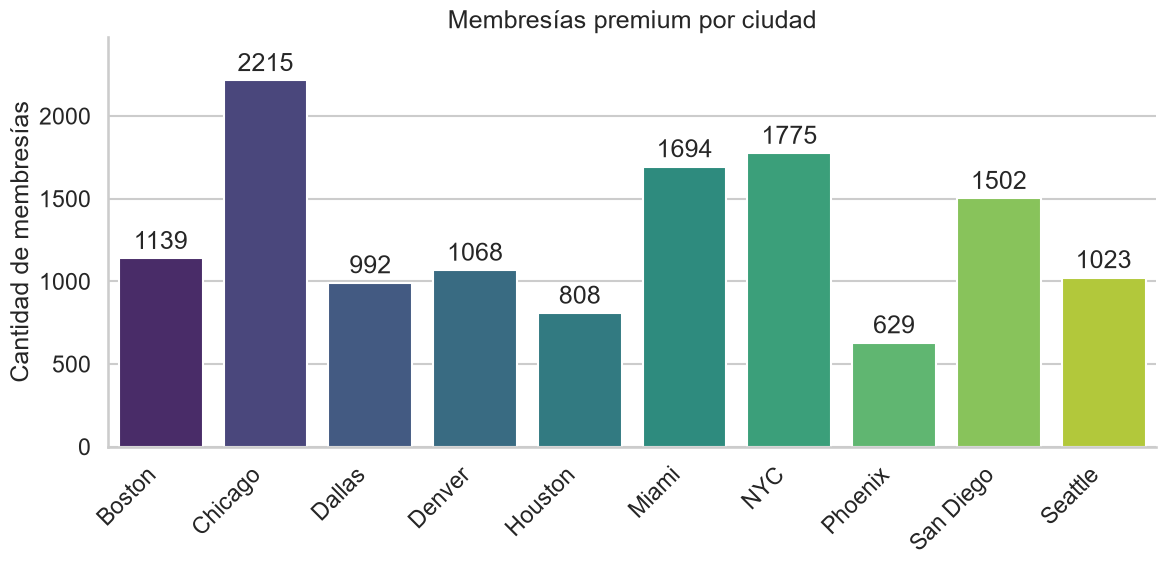

In [ ]:
# Creamos el gráfico de las ciudades  con membresia premium  con sus respetivas cantidades observando que las tres ciudades que cuentan con mayor cantidad son Chicago, NYC y Miami.
sns.set_theme(style="whitegrid", context="talk", palette="viridis")

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=solo_premium,
    x="ciudad_residencia",
    y="cantidad",
    hue="ciudad_residencia",
    palette="viridis",
    legend=False,
)

for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%d", padding=3)

ax.margins(y=0.12)  # deja espacio arriba para que los números no se salgan
ax.set(
    title="Membresías premium por ciudad",
    xlabel="",
    ylabel="Cantidad de membresías",
)
plt.xticks(rotation=45, ha="right")
sns.despine()
plt.tight_layout()
plt.show()


In [ ]:
# realizamos la comparación de las ciudades que mas mebresias presentan y de acuerdo a la cantidad de personas la proporción es mayor en la ciudad de Miami.
resumen_membresia = (
    df_pi.groupby("ciudad_residencia")
    .agg(
        clientes_totales=("membresia_premium", "size"),
        clientes_premium=(
            "membresia_premium",
            lambda x: (x == "Sí").sum()
        )
    )
)

resumen_membresia["porcentaje_premium"] = (
    resumen_membresia["clientes_premium"]
    / resumen_membresia["clientes_totales"]
    * 100
)

resumen_membresia.sort_values(
    "porcentaje_premium",
    ascending=False
)

,clientes_totales,clientes_premium,porcentaje_premium
ciudad_residencia,,,
Miami,3186,1694,53.170119
San Diego,3075,1502,48.845528
Seattle,2191,1023,46.691009
Boston,2547,1139,44.719278
Denver,2523,1068,42.330559
Phoenix,1511,629,41.628061
Chicago,5384,2215,41.140416
Dallas,2602,992,38.124520
NYC,4769,1775,37.219543


In [ ]:
# Agrupamos la data por  las columnas edad y consume_licor para observar las edades que mas registros presentan y podemos observar que a menor edad  se registra mayor consumo.
consumo_de_alcohol_por_edad= df_pi.groupby("edad")["consume_licor"].value_counts().reset_index(name="cantidad")

# Filtramos solo los que consumen licor
solo_consume_licor = consumo_de_alcohol_por_edad[consumo_de_alcohol_por_edad["consume_licor"] == "Sí"]

# Ordenamos de mayor a menor en cantidad de personas por edad
solo_consume_licor.sort_values("cantidad", ascending=False)

,edad,consume_licor,cantidad
18,27,Sí,471
16,26,Sí,456
20,28,Sí,452
12,24,Sí,447
22,29,Sí,444
...,...,...,...
111,73,Sí,188
115,75,Sí,188
117,76,Sí,187
113,74,Sí,181


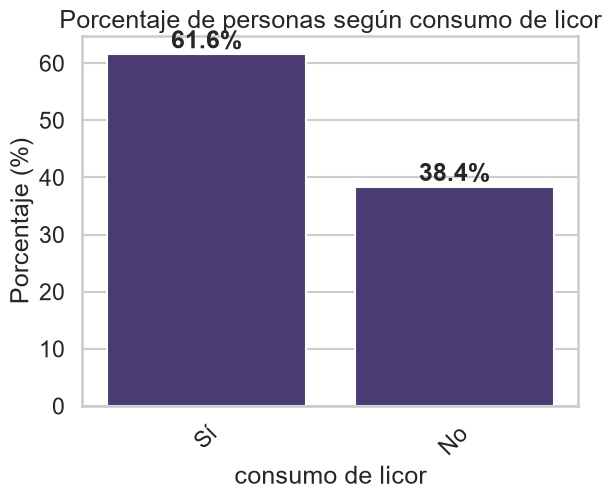

In [ ]:
# Graficamos el porcentaje de personas que consumnen licor  y las que no consumen observamos que el porcentaje es mayor en las personas que consumen 61,6 %, no consumen 38,4%.
plt.figure()

porcentajes = df_pi["consume_licor"].value_counts(normalize=True) * 100

ax = sns.barplot(
    x=porcentajes.index,
    y=porcentajes.values,
    order=porcentajes.sort_values(ascending=False).index  # ordena de mayor a menor
)

# Agregamos el porcentaje como texto encima de cada barra
for i, valor in enumerate(porcentajes.sort_values(ascending=False)):
    ax.text(i, valor + 1, f"{valor:.1f}%", ha="center", fontweight="bold")

plt.xticks(rotation=45)
plt.title("Porcentaje de personas según consumo de licor")
plt.ylabel("Porcentaje (%)")
plt.xlabel("consumo de licor")
plt.show()

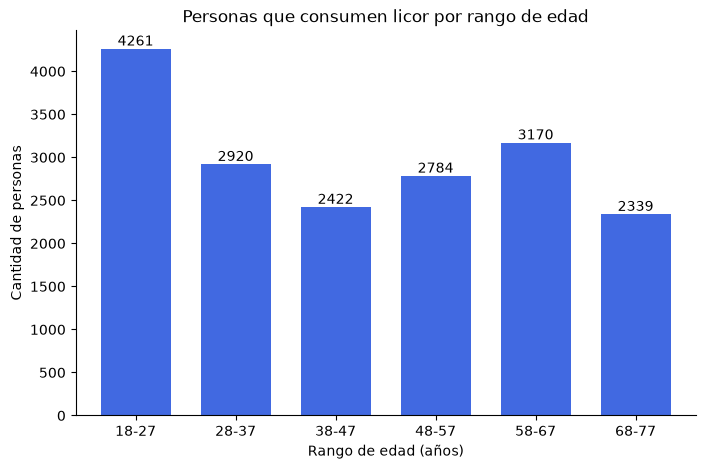

In [ ]:
# Realizamos el gráfico de las personas que consumen licor en rangos de edades de 10 años empezando desde los 18 años y podemos observar que las personas mas jovenes son quienes más consumen licor.

consumen = df_pi[df_pi["consume_licor"] == "Sí"]
cantidad = consumen["edad"].value_counts().sort_index()

rangos = pd.cut(consumen["edad"], bins=range(18, 80, 10), right=False)
cantidad = rangos.value_counts().sort_index()
cantidad.index = [f"{r.left}-{r.right - 1}" for r in cantidad.index]

ax = cantidad.plot.bar(color="royalblue", figsize=(8, 5), width=0.7)
ax.bar_label(ax.containers[0])
ax.set_title("Personas que consumen licor por rango de edad")
ax.set_xlabel("Rango de edad (años)")
ax.set_ylabel("Cantidad de personas")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=0)
plt.show()


In [ ]:
# Importamos la librería scipy con su paquete spearmanr para calcular el coeficiente de correlación de spearmanr el cual es mas robusto y no se ve afectao por valores muy extremos en el caso de la edad relacionado con el consumo de licor la relacion es negativa a mayor edad hay una tendencia a consumir menos licor.
from scipy.stats import spearmanr

datos = df_pi[["edad", "consume_licor"]]
rho, p = spearmanr(datos["edad"], datos["consume_licor"])
print(f"rho = {rho:.3f}, p = {p:.4f}")


rho = -0.202, p = 0.0000
